In [1]:
import pandas as pd
import numpy as np
import sklearn
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")
print("Pandas version:", pd.__version__)

All libraries imported successfully!
Pandas version: 2.3.3


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configure display options to see all columns
pd.set_option('display.max_columns', None)
sns.set_theme(style="whitegrid")

print("Libraries loaded successfully!")

Libraries loaded successfully!


In [3]:
# Replace 'your_dataset.csv' with your actual dataset filename
data_path = "../data/your_dataset.csv"

try:
    df = pd.read_csv(data_path)
    print(f"Dataset loaded successfully with shape: {df.shape}")
except FileNotFoundError:
    print(f"File not found at {data_path}. Please check your file path.")

File not found at ../data/your_dataset.csv. Please check your file path.


In [10]:
import pandas as pd

# Correct relative path from notebooks/ folder to data/ folder
data_path = "../data/house_prices.csv"

# Load the dataset
df = pd.read_csv(data_path)

# Verify it loaded correctly
print(f"Dataset loaded successfully with shape: {df.shape}")
display(df.head())

EmptyDataError: No columns to parse from file

# 01 - Exploratory Data Analysis (EDA)
**Project:** House Prices Prediction Capstone  
**Objective:** Perform initial data cleaning, inspect data structure, examine summary statistics, analyze missing values, and explore feature distributions for target modeling.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configure display and plot settings
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

print("Environment configured successfully!")
print("Pandas version:", pd.__version__)
print("Seaborn version:", sns.__version__)

## 1. Load Dataset
Loading the housing dataset from the local `data/` directory into a Pandas DataFrame.

In [15]:
# Relative path from notebooks/ to data/
data_path = "../data/house_prices.csv"

try:
    df = pd.read_csv(data_path)
    print(f"Dataset successfully loaded into memory!")
    print(f"Total Rows: {df.shape[0]} | Total Columns: {df.shape[1]}")
except pd.errors.EmptyDataError:
    print("Error: 'house_prices.csv' is currently empty. Please ensure your raw CSV data is pasted into the file.")
except FileNotFoundError:
    print(f"Error: Could not locate file at {data_path}. Verify the filename and directory structure.")

Dataset successfully loaded into memory!
Total Rows: 545 | Total Columns: 13


## 2. General Data Structure & Statistics
Inspecting the first few records, data types, missing value totals, and statistical distribution summaries.

In [16]:
# View first 5 rows
print("--- First 5 Rows ---")
display(df.head())

# Concise summary of columns, non-null values, and dtypes
print("\n--- Data Info ---")
df.info()

# Summary statistics for numerical variables
print("\n--- Summary Statistics (Numerical Features) ---")
display(df.describe())

--- First 5 Rows ---


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished



--- Data Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   price             545 non-null    int64 
 1   area              545 non-null    int64 
 2   bedrooms          545 non-null    int64 
 3   bathrooms         545 non-null    int64 
 4   stories           545 non-null    int64 
 5   mainroad          545 non-null    object
 6   guestroom         545 non-null    object
 7   basement          545 non-null    object
 8   hotwaterheating   545 non-null    object
 9   airconditioning   545 non-null    object
 10  parking           545 non-null    int64 
 11  prefarea          545 non-null    object
 12  furnishingstatus  545 non-null    object
dtypes: int64(6), object(7)
memory usage: 55.5+ KB

--- Summary Statistics (Numerical Features) ---


,price,area,bedrooms,bathrooms,stories,parking
count,5.450000e+02,545.000000,545.000000,545.000000,545.000000,545.000000
mean,4.766729e+06,5150.541284,2.965138,1.286239,1.805505,0.693578
std,1.870440e+06,2170.141023,0.738064,0.502470,0.867492,0.861586
min,1.750000e+06,1650.000000,1.000000,1.000000,1.000000,0.000000
25%,3.430000e+06,3600.000000,2.000000,1.000000,1.000000,0.000000
50%,4.340000e+06,4600.000000,3.000000,1.000000,2.000000,0.000000
75%,5.740000e+06,6360.000000,3.000000,2.000000,2.000000,1.000000
max,1.330000e+07,16200.000000,6.000000,4.000000,4.000000,3.000000


## 3. Missing Value Analysis
Identify columns with missing values and evaluate their percentage relative to total observations.

In [17]:
# Compute missing counts and percentages
missing_count = df.isnull().sum()
missing_percent = (df.isnull().sum() / len(df)) * 100

missing_df = pd.DataFrame({
    'Missing Count': missing_count,
    'Percentage (%)': missing_percent
})

# Filter out features with no missing data
missing_df = missing_df[missing_df['Missing Count'] > 0].sort_values(by='Missing Count', ascending=False)

if not missing_df.empty:
    print(f"Found {len(missing_df)} feature(s) with missing values:")
    display(missing_df)
else:
    print("No missing values found across all features!")

No missing values found across all features!


## 4. Target Distribution Analysis
Explore the distribution of the target variable (`SalePrice`) to test for skewness or outliers.

In [18]:
if 'SalePrice' in df.columns:
    plt.figure(figsize=(10, 5))
    sns.histplot(df['SalePrice'], kde=True, color='skyblue')
    plt.title('Distribution of House Sale Prices', fontsize=14, fontweight='bold')
    plt.xlabel('Sale Price ($)')
    plt.ylabel('Frequency')
    plt.show()
    
    print("SalePrice Skewness:", df['SalePrice'].skew())
else:
    print("Target column 'SalePrice' not found in dataset columns.")

Target column 'SalePrice' not found in dataset columns.


In [19]:
# Print all column names in the dataset
print("Available columns in your dataset:")
print(list(df.columns))

Available columns in your dataset:
['price', 'area', 'bedrooms', 'bathrooms', 'stories', 'mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'parking', 'prefarea', 'furnishingstatus']


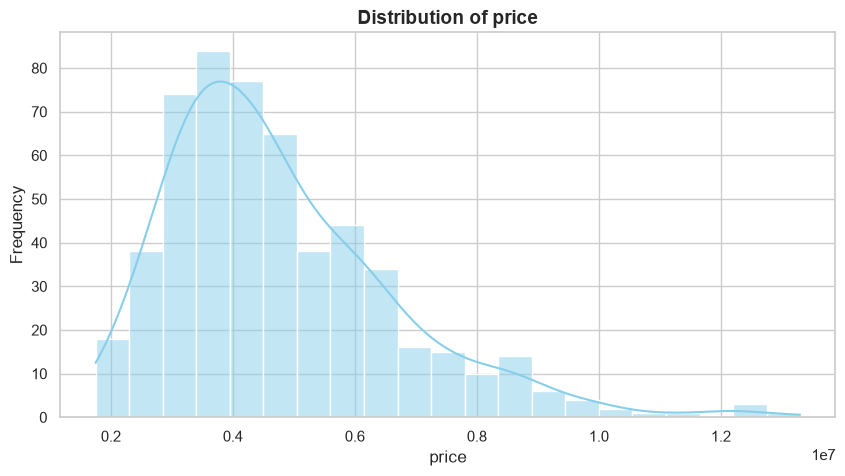

price Skewness: 1.2122388370279802


In [20]:
target_col = 'price' # Replace with your actual target column name from the list above

if target_col in df.columns:
    plt.figure(figsize=(10, 5))
    sns.histplot(df[target_col], kde=True, color='skyblue')
    plt.title(f'Distribution of {target_col}', fontsize=14, fontweight='bold')
    plt.xlabel(target_col)
    plt.ylabel('Frequency')
    plt.show()
    
    print(f"{target_col} Skewness:", df[target_col].skew())
else:
    print(f"Target column '{target_col}' not found.")

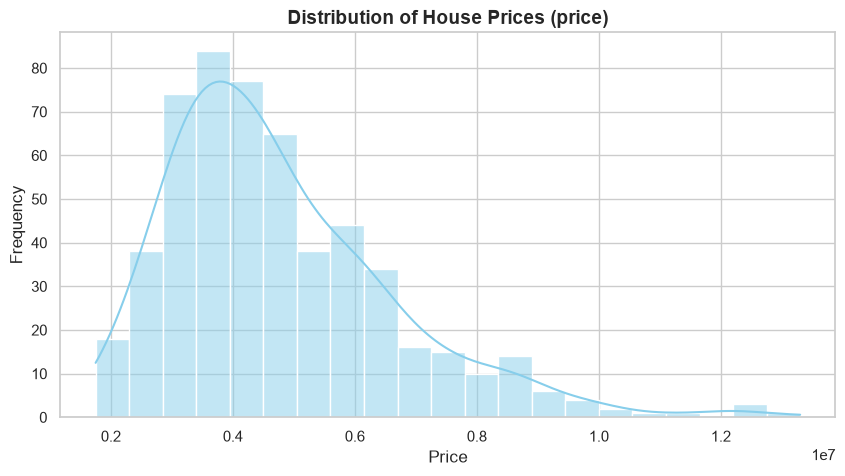

price Skewness: 1.2122388370279802


In [21]:
target_col = 'price'

if target_col in df.columns:
    plt.figure(figsize=(10, 5))
    sns.histplot(df[target_col], kde=True, color='skyblue')
    plt.title(f'Distribution of House Prices ({target_col})', fontsize=14, fontweight='bold')
    plt.xlabel('Price')
    plt.ylabel('Frequency')
    plt.show()
    
    print(f"{target_col} Skewness:", df[target_col].skew())
else:
    print(f"Target column '{target_col}' not found.")

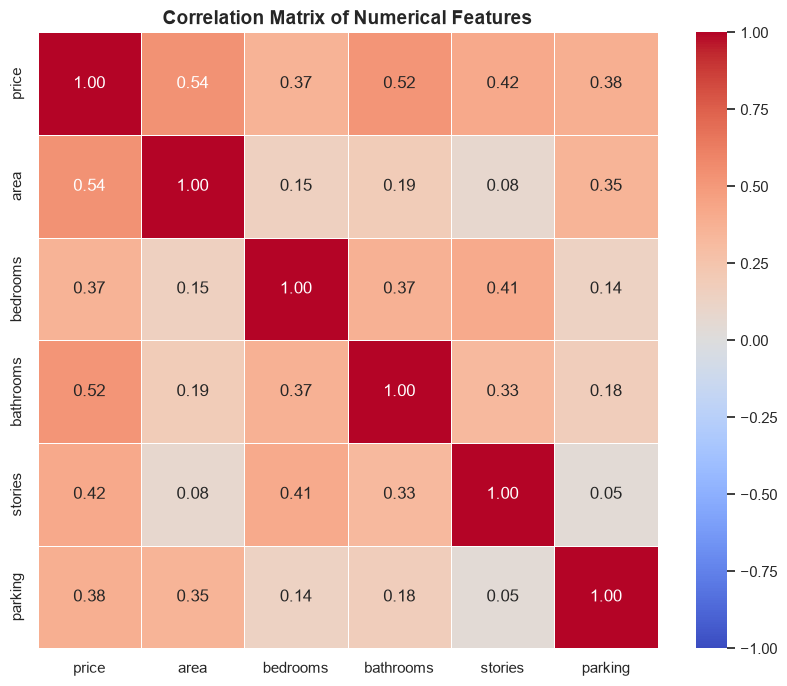

--- Correlation with Price ---
price        1.000000
area         0.535997
bathrooms    0.517545
stories      0.420712
parking      0.384394
bedrooms     0.366494
Name: price, dtype: float64


In [22]:
# Select only numerical columns for correlation
numerical_cols = df.select_dtypes(include=['int64', 'float64'])

# Compute correlation matrix
corr_matrix = numerical_cols.corr()

# Plot the heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5, vmin=-1, vmax=1)
plt.title('Correlation Matrix of Numerical Features', fontsize=14, fontweight='bold')
plt.show()

# Print correlations specifically with 'price'
print("--- Correlation with Price ---")
print(corr_matrix['price'].sort_values(ascending=False))

In [23]:
# Identify categorical columns
categorical_cols = df.select_dtypes(include=['object']).columns.tolist()
print("Categorical columns:", categorical_cols)

# Show unique values for each categorical column to see their format
for col in categorical_cols:
    print(f"\n{col}: {df[col].unique()}")

Categorical columns: ['mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'prefarea', 'furnishingstatus']

mainroad: ['yes' 'no']

guestroom: ['no' 'yes']

basement: ['no' 'yes']

hotwaterheating: ['no' 'yes']

airconditioning: ['yes' 'no']

prefarea: ['yes' 'no']

furnishingstatus: ['furnished' 'semi-furnished' 'unfurnished']


## 5. Data Preprocessing & Feature Encoding
Converting categorical text columns into numerical formats (binary mapping and one-hot encoding) and separating features ($X$) from the target variable ($y$).

In [24]:
# 1. Identify categorical columns
categorical_cols = df.select_dtypes(include=['object']).columns.tolist()
print("Categorical columns found:", categorical_cols)

# 2. Inspect unique values for binary/categorical features
for col in categorical_cols:
    print(f"{col}: {df[col].unique()}")

# 3. Map binary 'yes'/'no' columns to 1 and 0
binary_cols = ['mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'prefarea']
for col in binary_cols:
    if col in df.columns:
        df[col] = df[col].map({'yes': 1, 'no': 0})

# 4. One-hot encode multi-class categorical columns (e.g., furnishingstatus)
df = pd.get_dummies(df, columns=['furnishingstatus'], drop_first=True)

print("\n--- Preprocessed Data Head ---")
display(df.head())

# 5. Split into Features (X) and Target (y)
X = df.drop(columns=['price'])
y = df['price']

print(f"\nFeatures shape (X): {X.shape}")
print(f"Target shape (y): {y.shape}")

Categorical columns found: ['mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'prefarea', 'furnishingstatus']
mainroad: ['yes' 'no']
guestroom: ['no' 'yes']
basement: ['no' 'yes']
hotwaterheating: ['no' 'yes']
airconditioning: ['yes' 'no']
prefarea: ['yes' 'no']
furnishingstatus: ['furnished' 'semi-furnished' 'unfurnished']

--- Preprocessed Data Head ---


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus_semi-furnished,furnishingstatus_unfurnished
0,13300000,7420,4,2,3,1,0,0,0,1,2,1,False,False
1,12250000,8960,4,4,4,1,0,0,0,1,3,0,False,False
2,12250000,9960,3,2,2,1,0,1,0,0,2,1,True,False
3,12215000,7500,4,2,2,1,0,1,0,1,3,1,False,False
4,11410000,7420,4,1,2,1,1,1,0,1,2,0,False,False



Features shape (X): (545, 13)
Target shape (y): (545,)


## 6. Train-Test Split & Baseline Model
Splitting the preprocessed data into training (80%) and testing (20%) sets, training a baseline Linear Regression model, and evaluating performance using Mean Squared Error ($MSE$) and $R^2$ Score.

In [25]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# 1. Split data into train (80%) and test (20%) sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Training set shape: X_train = {X_train.shape}, y_train = {y_train.shape}")
print(f"Testing set shape:  X_test = {X_test.shape}, y_test = {y_test.shape}")

# 2. Initialize and train the Linear Regression model
model = LinearRegression()
model.fit(X_train, y_train)

# 3. Make predictions on the test set
y_pred = model.predict(X_test)

# 4. Evaluate model performance
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("\n--- Baseline Model Performance ---")
print(f"Root Mean Squared Error (RMSE): ${rmse:,.2f}")
print(f"R-squared (R² ) Score: {r2:.4f}")

# 5. Display model coefficients to see feature importance
coefficients = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': model.coef_
}).sort_values(by='Coefficient', ascending=False)

print("\n--- Feature Coefficients ---")
display(coefficients)

Training set shape: X_train = (436, 13), y_train = (436,)
Testing set shape:  X_test = (109, 13), y_test = (109,)

--- Baseline Model Performance ---
Root Mean Squared Error (RMSE): $1,324,506.96
R-squared (R² ) Score: 0.6529

--- Feature Coefficients ---


,Feature,Coefficient
2,bathrooms,1.094445e+06
8,airconditioning,7.914267e+05
7,hotwaterheating,6.846499e+05
10,prefarea,6.298906e+05
3,stories,4.074766e+05
6,basement,3.902512e+05
4,mainroad,3.679199e+05
5,guestroom,2.316100e+05
9,parking,2.248419e+05
1,bedrooms,7.677870e+04


## 7. Saving the Trained Model
Serializing and saving the trained Linear Regression model to the local `models/` folder using `joblib`.

In [26]:
import joblib
import os

# Ensure models directory exists
os.makedirs('../models', exist_ok=True)

# Save the model
model_path = '../models/linear_regression_model.pkl'
joblib.dump(model, model_path)

print(f"Model successfully saved to: {model_path}")

# Verification: Load the model back to test it
loaded_model = joblib.load(model_path)
print("Verification test - Loaded model prediction on first test sample:", loaded_model.predict(X_test.iloc[[0]]))

Model successfully saved to: ../models/linear_regression_model.pkl
Verification test - Loaded model prediction on first test sample: [5164653.90033968]


## 8. Training a Random Forest Regressor
Training an ensemble Random Forest model to compare non-linear performance against our baseline Linear Regression.

In [27]:
from sklearn.ensemble import RandomForestRegressor

# 1. Initialize and train the Random Forest Regressor
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

# 2. Make predictions
y_pred_rf = rf_model.predict(X_test)

# 3. Evaluate performance
rf_mse = mean_squared_error(y_test, y_pred_rf)
rf_rmse = np.sqrt(rf_mse)
rf_r2 = r2_score(y_test, y_pred_rf)

print("--- Random Forest Model Performance ---")
print(f"Root Mean Squared Error (RMSE): ${rf_rmse:,.2f}")
print(f"R-squared (R² ) Score: {rf_r2:.4f}")

# 4. Save the Random Forest model as well
rf_model_path = '../models/random_forest_model.pkl'
joblib.dump(rf_model, rf_model_path)
print(f"\nRandom Forest model saved to: {rf_model_path}")

--- Random Forest Model Performance ---
Root Mean Squared Error (RMSE): $1,401,496.84
R-squared (R² ) Score: 0.6114

Random Forest model saved to: ../models/random_forest_model.pkl


## 9. Model Evaluation & Visualization
Plotting Actual vs. Predicted house prices to visually assess model performance.

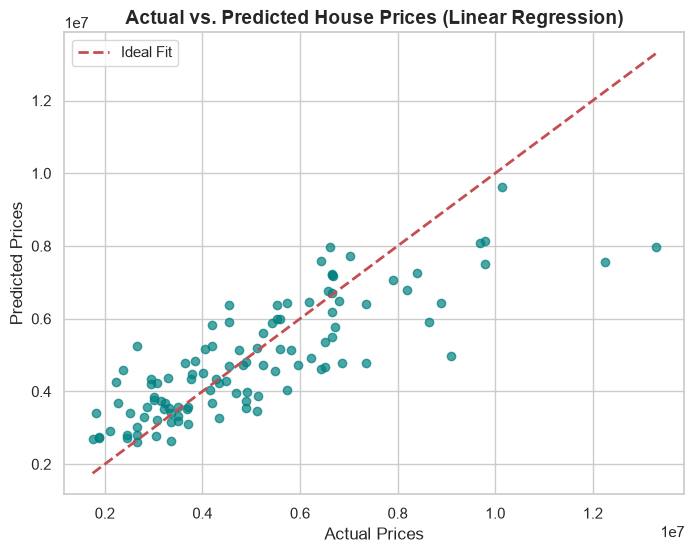

In [28]:
# Use Linear Regression predictions since it had the higher R² score
y_pred_best = y_pred 

plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred_best, alpha=0.7, color='teal')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Ideal Fit')
plt.xlabel('Actual Prices', fontsize=12)
plt.ylabel('Predicted Prices', fontsize=12)
plt.title('Actual vs. Predicted House Prices (Linear Regression)', fontsize=14, fontweight='bold')
plt.legend()
plt.show()